## Lab 2: Seaborn (From Matplolib and pandas to seaborn)

In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")

1. Hacer el analisis estadístico de las variables: Millas por galón (mpg) vs potencia (horsepower) in the dataset: millas_por_galon.csv. Contruya el fit al $95$ C.L. Usar `seaborn`. Give some conclusions.

2. Descargar el dataframe : https://github.com/anferivera/SDdiracDM/blob/master/general-scan.csv
  desde GitHUb y reconstruir la figura 6 del [trabajo](https://journals.aps.org/prd/abstract/10.1103/PhysRevD.100.035029). Para ello usar `seaborn` y `matplolib`.

  * $M_N=h_s\dfrac{v_s}{\sqrt{2}}$
  * $v_s =$ vS
  * $h_s=$ YRC
  * $M_\Psi=$ MDF
  * $M_{\chi_1^0}=$ mChi1
  * $\Omega_{\chi_1^0}=$ Omega
  * $\Omega_{DM}=0.12$

## Punto 1

### 1.1 Carga y limpieza de datos

In [2]:
filename = "/home/thomas/Desktop/Forked_Computacional_1/Fisica_Computacional_1/Sesiones/seaborn/millas_por_galon.csv"

try:
    df = pd.read_csv(filename)
except FileNotFoundError:
    # Si el notebook se corre en otro PC, se usa la misma tabla que trae seaborn
    df = sns.load_dataset("mpg")

df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


`horsepower` tiene **6 valores faltantes** (392 de 398). Se eliminan esas filas antes de hacer estadística y ajustes; si no, `np.polyfit` y `scipy` fallan o dan `nan`.

In [4]:
print("Valores faltantes por columna:\n", df[["mpg", "horsepower"]].isna().sum())

datos = df.dropna(subset=["mpg", "horsepower"]).copy()
x = datos["horsepower"].to_numpy()
y = datos["mpg"].to_numpy()
n = len(datos)
print(f"\nFilas usadas en el análisis: {n}")

Valores faltantes por columna:
 mpg           0
horsepower    6
dtype: int64

Filas usadas en el análisis: 392


### 1.2 Estadística descriptiva

In [5]:
resumen = datos[["mpg", "horsepower"]].describe().T
resumen["mediana"] = datos[["mpg", "horsepower"]].median()
resumen["asimetría"] = datos[["mpg", "horsepower"]].skew()
resumen["curtosis"] = datos[["mpg", "horsepower"]].kurt()
resumen

,count,mean,std,min,25%,50%,75%,max,mediana,asimetría,curtosis
mpg,392.0,23.445918,7.805007,9.0,17.0,22.75,29.0,46.6,22.75,0.457092,-0.515993
horsepower,392.0,104.469388,38.491160,46.0,75.0,93.50,126.0,230.0,93.50,1.087326,0.696947


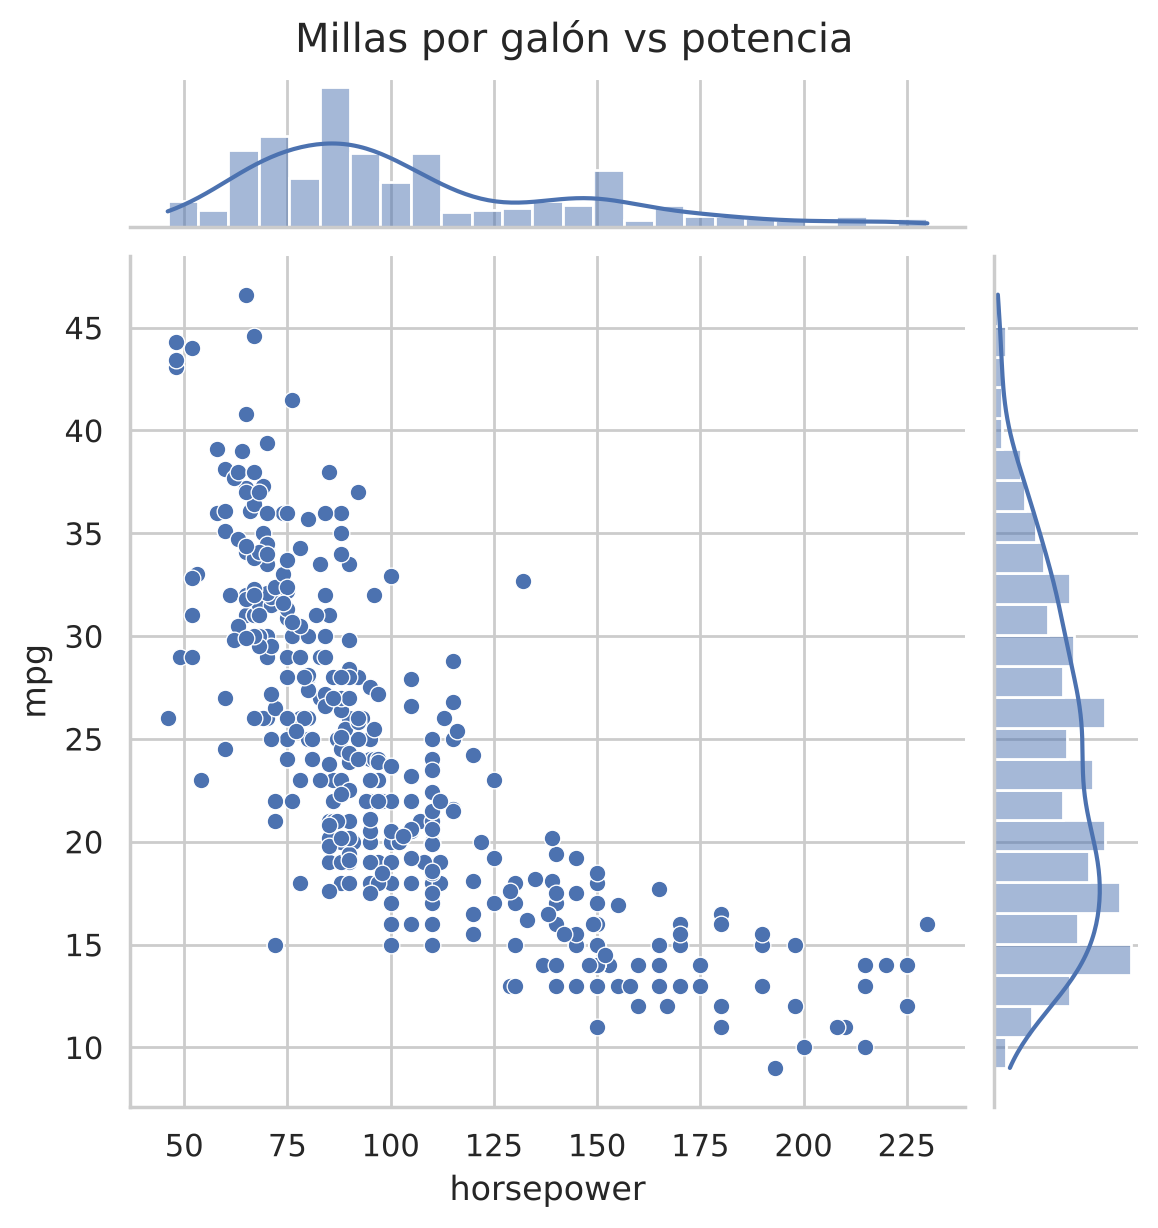

In [6]:
# Distribución de cada variable y relación conjunta
g = sns.jointplot(data=datos, x="horsepower", y="mpg", kind="scatter",
                  marginal_kws=dict(bins=25, kde=True), height=6)
g.figure.suptitle("Millas por galón vs potencia", y=1.02)
plt.show()

### 1.3 Correlación

* **Pearson** mide relación *lineal*.
* **Spearman** mide relación *monótona* (no necesariamente lineal).

In [7]:
r_p, p_p = stats.pearsonr(x, y)
r_s, p_s = stats.spearmanr(x, y)

print(f"Pearson  r   = {r_p:.4f}   (p-valor = {p_p:.2e})")
print(f"Spearman rho = {r_s:.4f}   (p-valor = {p_s:.2e})")

Pearson  r   = -0.7784   (p-valor = 7.03e-81)
Spearman rho = -0.8536   (p-valor = 1.62e-112)


$|\rho_{Spearman}| > |r_{Pearson}|$: la relación es fuertemente decreciente pero **no lineal** (curva). Eso justifica probar un ajuste polinómico.

### 1.4 Elección del grado del polinomio

Se ajustan polinomios de grado 1 a 4 con `np.polyfit` y se comparan con $R^2$, $R^2$ ajustado, RMSE y los criterios de información AIC y BIC (penalizan los parámetros de más; **menor es mejor**).

In [8]:
def metricas(grado):
    coef = np.polyfit(x, y, grado)
    res = y - np.polyval(coef, x)
    sse = np.sum(res**2)
    sst = np.sum((y - y.mean())**2)
    k = grado + 1                       # número de parámetros
    r2 = 1 - sse / sst
    r2_aj = 1 - (1 - r2) * (n - 1) / (n - k)
    rmse = np.sqrt(sse / n)
    aic = n * np.log(sse / n) + 2 * k
    bic = n * np.log(sse / n) + k * np.log(n)
    return dict(grado=grado, R2=r2, R2_ajustado=r2_aj, RMSE=rmse, AIC=aic, BIC=bic)

tabla = pd.DataFrame([metricas(g) for g in range(1, 5)]).set_index("grado")
tabla.round(4)

,R2,R2_ajustado,RMSE,AIC,BIC
grado,,,,,
1,0.6059,0.6049,4.8932,1248.8758,1256.8184
2,0.6876,0.6860,4.3572,1159.9057,1171.8195
3,0.6882,0.6858,4.3526,1161.0835,1176.9685
4,0.6893,0.6861,4.3447,1161.6603,1181.5166


El salto grande ocurre de grado 1 a grado 2. Los grados 3 y 4 casi no mejoran $R^2$ y **empeoran** AIC y BIC, así que el modelo elegido es el **cuadrático** (grado 2). Usar `order=3` (como en la versión anterior) añade un parámetro que no aporta.

### 1.5 Ecuación del ajuste y sus incertidumbres

In [9]:
grado = 2
coef, cov = np.polyfit(x, y, grado, cov=True)
err = np.sqrt(np.diag(cov))
a, b, c = coef

print("Ajuste:  mpg = a·hp² + b·hp + c\n")
for nombre, v, e in zip(["a", "b", "c"], coef, err):
    print(f"  {nombre} = {v: .4e} ± {e:.1e}")

print(f"\nmpg(hp) = ({a:.5f}) hp² + ({b:.4f}) hp + ({c:.2f})")
print(f"R² = {tabla.loc[grado, 'R2']:.4f}    RMSE = {tabla.loc[grado, 'RMSE']:.2f} mpg")
print(f"Vértice de la parábola: hp = {-b/(2*a):.0f}")

Ajuste:  mpg = a·hp² + b·hp + c

  a =  1.2305e-03 ± 1.2e-04
  b = -4.6619e-01 ± 3.1e-02
  c =  5.6900e+01 ± 1.8e+00

mpg(hp) = (0.00123) hp² + (-0.4662) hp + (56.90)
R² = 0.6876    RMSE = 4.36 mpg
Vértice de la parábola: hp = 189


### 1.6 Ajuste con banda de confianza al 95 % C.L. (seaborn)

`sns.regplot(..., order=2, ci=95)` dibuja el polinomio y la banda de confianza del 95 % (calculada por *bootstrap*). Encima se escribe la ecuación del ajuste.

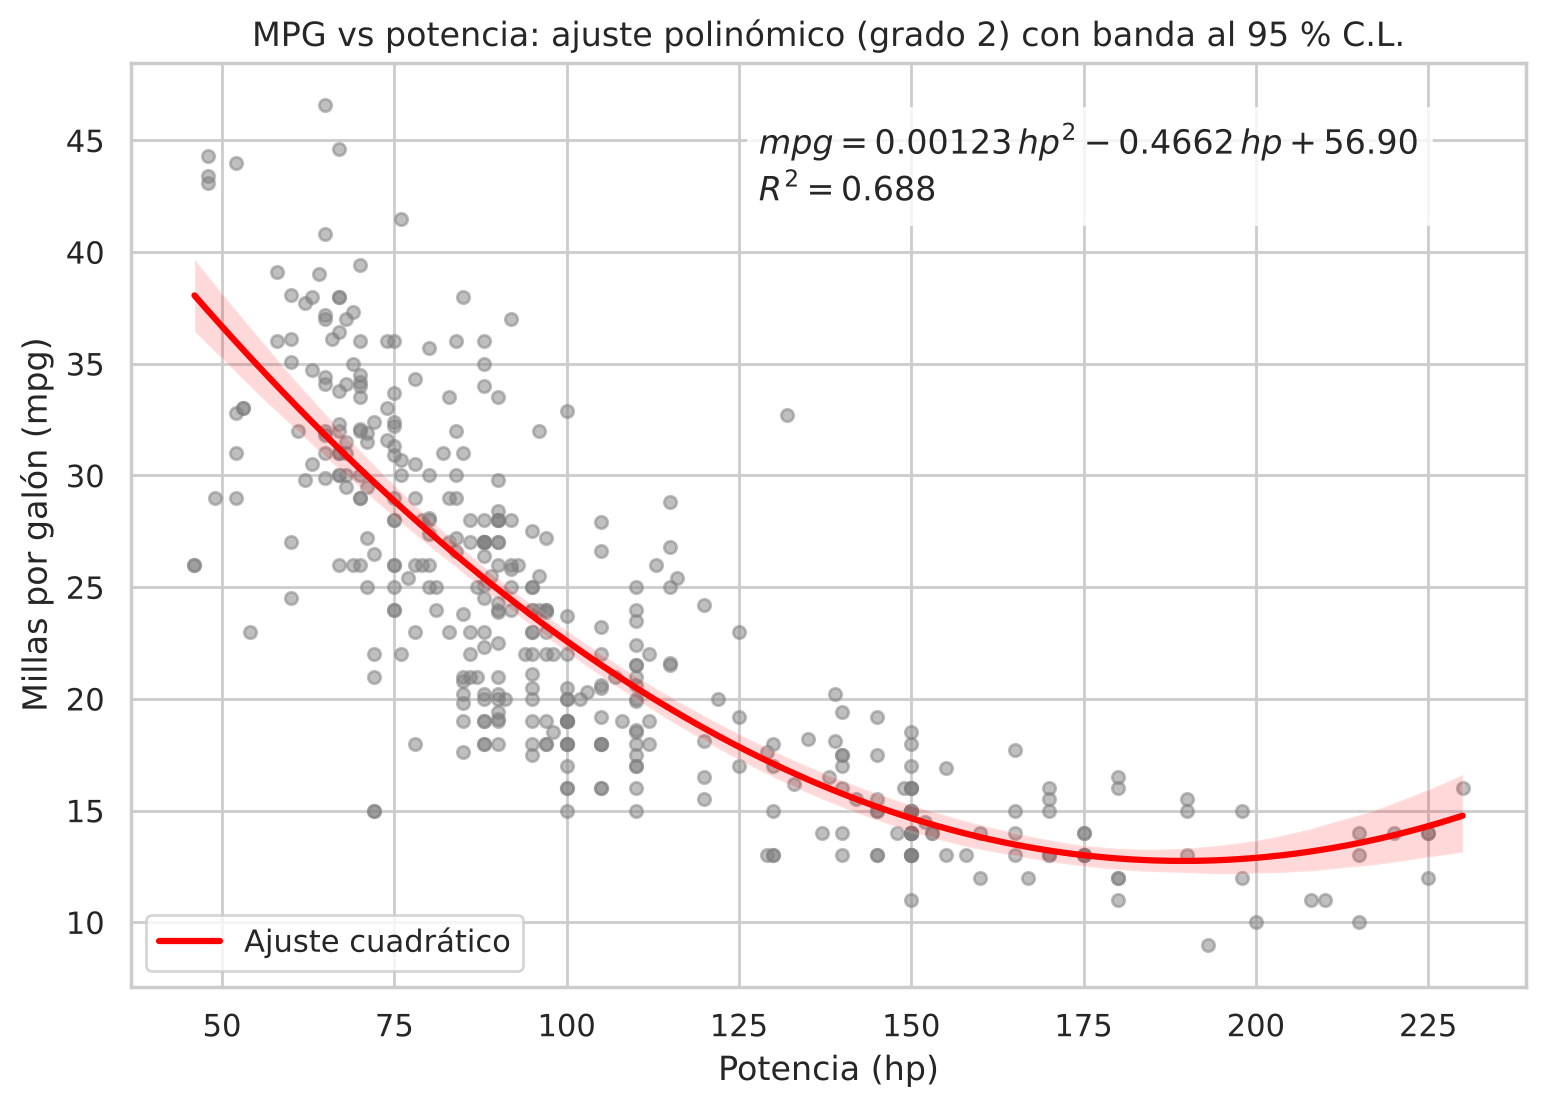

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(
    data=datos, x="horsepower", y="mpg",
    order=grado, ci=95, n_boot=1000, seed=0,
    scatter_kws={"alpha": 0.5, "s": 20, "color": "gray"},
    line_kws={"color": "red", "label": "Ajuste cuadrático"},
    ax=ax,
)
texto = (rf"$mpg = {a:.5f}\,hp^2 {b:+.4f}\,hp {c:+.2f}$" "\n"
         rf"$R^2 = {tabla.loc[grado, 'R2']:.3f}$")
ax.text(0.45, 0.85, texto, transform=ax.transAxes, fontsize=12,
        bbox=dict(facecolor="white", alpha=0.8))
ax.set(title="MPG vs potencia: ajuste polinómico (grado 2) con banda al 95 % C.L.",
       xlabel="Potencia (hp)", ylabel="Millas por galón (mpg)")
ax.legend(loc="lower left")
plt.show()

### 1.7 Verificación analítica de la banda del 95 %

La banda de `seaborn` se puede comprobar con la matriz de covarianza de los parámetros:

* **Banda de confianza** (dónde está la *curva media*): $\hat y \pm t_{0.975,\,n-3}\sqrt{X\,\Sigma\,X^T}$
* **Banda de predicción** (dónde cae un *carro nuevo*): $\hat y \pm t_{0.975,\,n-3}\sqrt{X\,\Sigma\,X^T + s^2}$

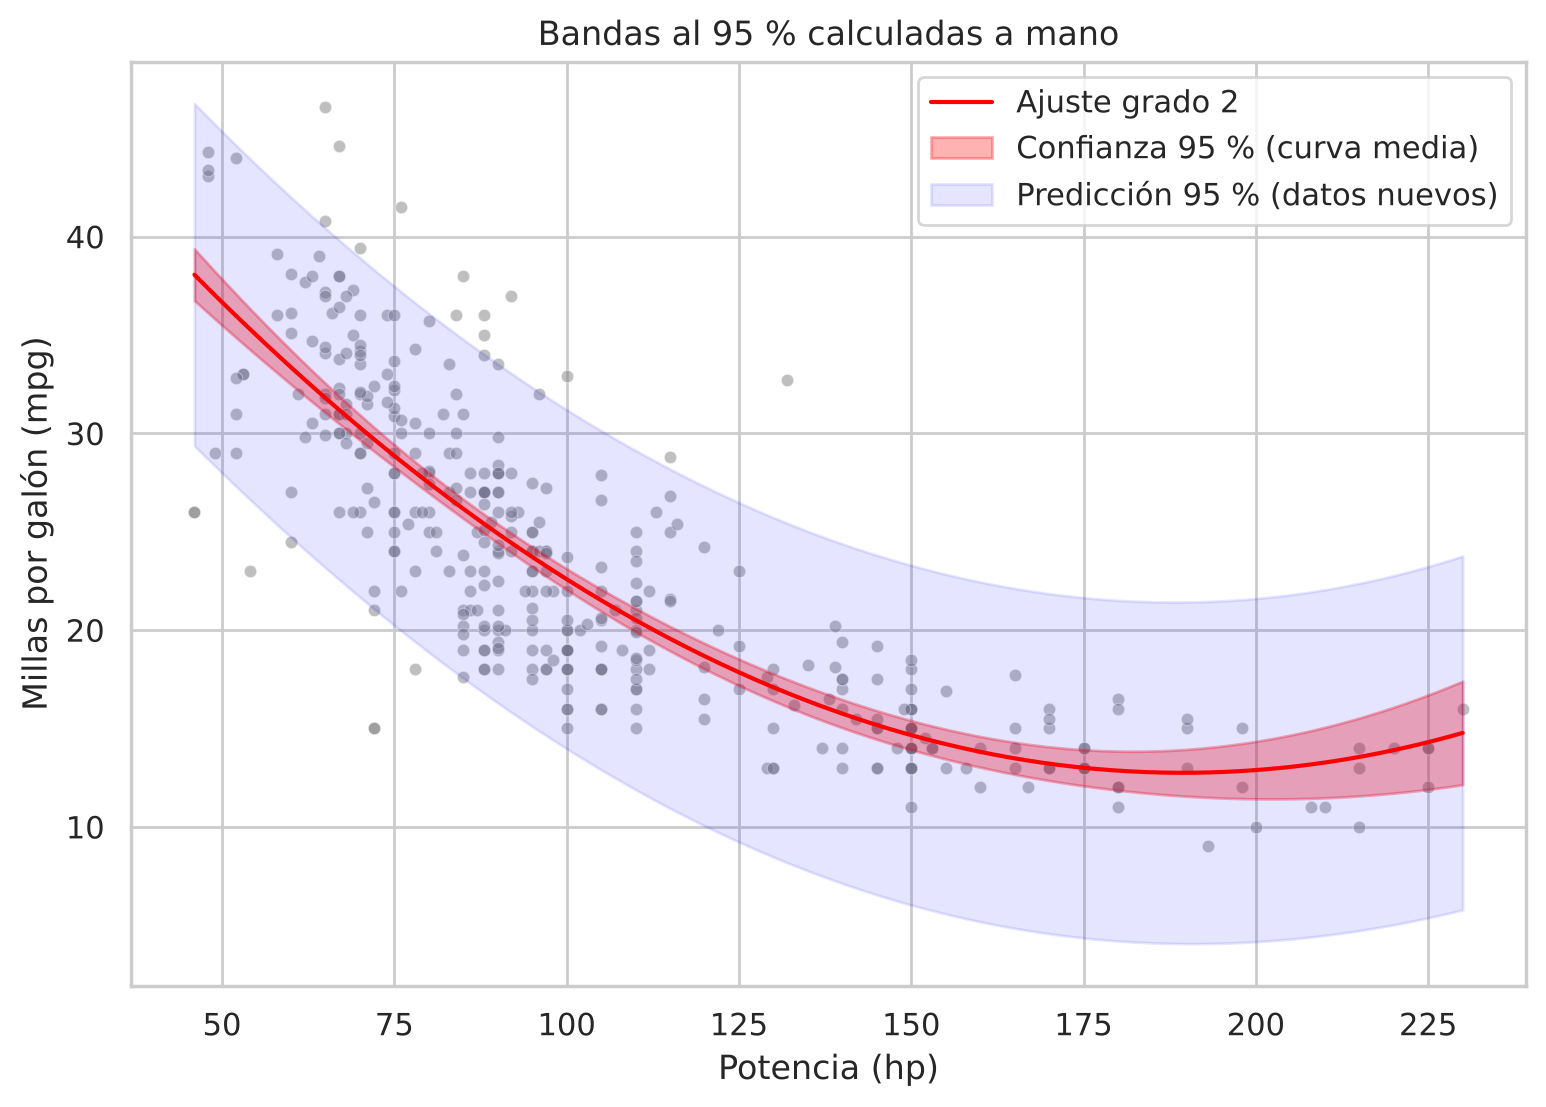

Fracción de datos dentro de la banda de predicción: 94.6% (lo esperado es ~95 %)


In [11]:
x_graf = np.linspace(x.min(), x.max(), 300)
X = np.vander(x_graf, grado + 1)            # columnas [hp², hp, 1]
y_graf = X @ coef

t = stats.t.ppf(0.975, n - (grado + 1))
s2 = np.sum((y - np.polyval(coef, x))**2) / (n - (grado + 1))
var_media = np.einsum("ij,jk,ik->i", X, cov, X)

banda_conf = t * np.sqrt(var_media)
banda_pred = t * np.sqrt(var_media + s2)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=datos, x="horsepower", y="mpg", color="gray", alpha=0.5, s=20, ax=ax)
ax.plot(x_graf, y_graf, color="red", label="Ajuste grado 2")
ax.fill_between(x_graf, y_graf - banda_conf, y_graf + banda_conf,
                color="red", alpha=0.3, label="Confianza 95 % (curva media)")
ax.fill_between(x_graf, y_graf - banda_pred, y_graf + banda_pred,
                color="blue", alpha=0.1, label="Predicción 95 % (datos nuevos)")
ax.set(xlabel="Potencia (hp)", ylabel="Millas por galón (mpg)",
       title="Bandas al 95 % calculadas a mano")
ax.legend()
plt.show()

dentro = np.abs(y - np.polyval(coef, x)) <= t * np.sqrt(np.einsum("ij,jk,ik->i", np.vander(x, 3), cov, np.vander(x, 3)) + s2)
print(f"Fracción de datos dentro de la banda de predicción: {dentro.mean():.1%} (lo esperado es ~95 %)")

### 1.8 Análisis de residuos

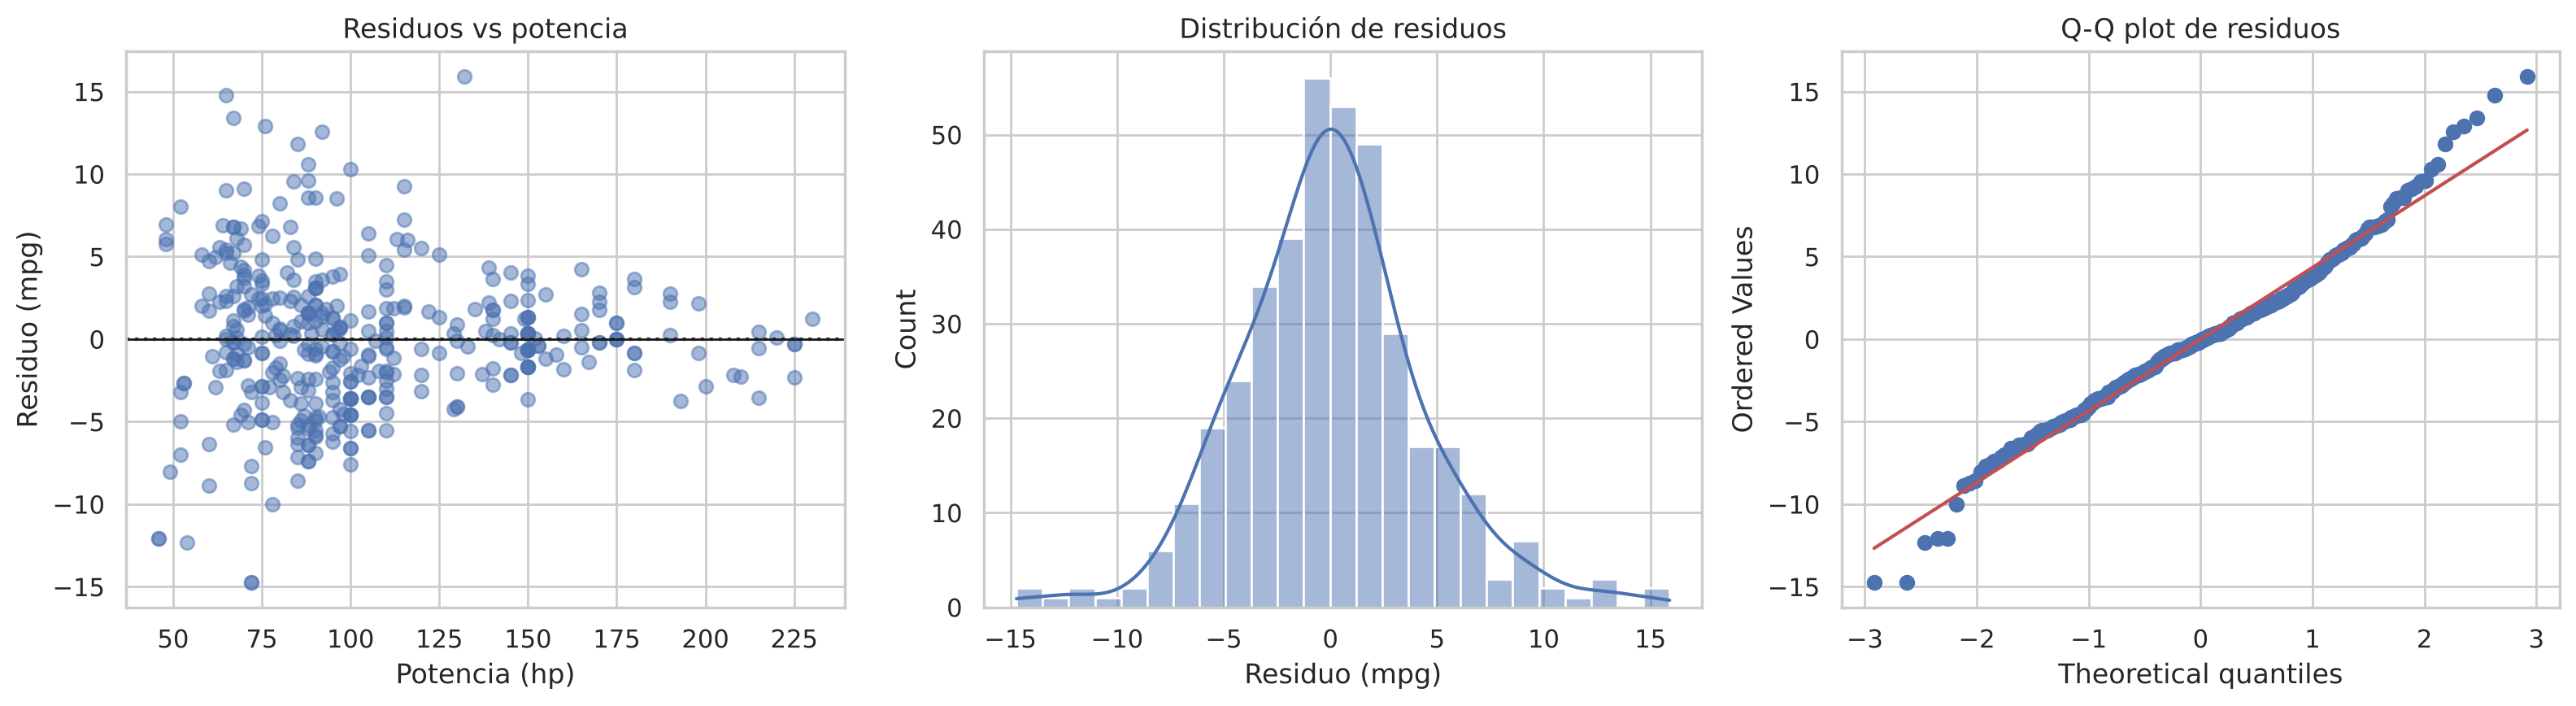

Media de residuos = 7.25e-15
Shapiro-Wilk: W = 0.9827, p = 1.21e-04


In [12]:
residuos = y - np.polyval(coef, x)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.residplot(data=datos, x="horsepower", y="mpg", order=grado,
              scatter_kws={"alpha": 0.5}, ax=axes[0])
axes[0].axhline(0, color="k", lw=1)
axes[0].set(title="Residuos vs potencia", xlabel="Potencia (hp)", ylabel="Residuo (mpg)")

sns.histplot(residuos, kde=True, bins=25, ax=axes[1])
axes[1].set(title="Distribución de residuos", xlabel="Residuo (mpg)")

stats.probplot(residuos, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot de residuos")

plt.tight_layout()
plt.show()

w, p_w = stats.shapiro(residuos)
print(f"Media de residuos = {residuos.mean():.2e}")
print(f"Shapiro-Wilk: W = {w:.4f}, p = {p_w:.2e}")

### 1.9 Efecto del origen del vehículo

          mpg             horsepower             
         mean   std count       mean    std count
origin                                           
europe  27.60  6.58    68      80.56  20.16    68
japan   30.45  6.09    79      79.84  17.82    79
usa     20.03  6.44   245     119.05  39.90   245


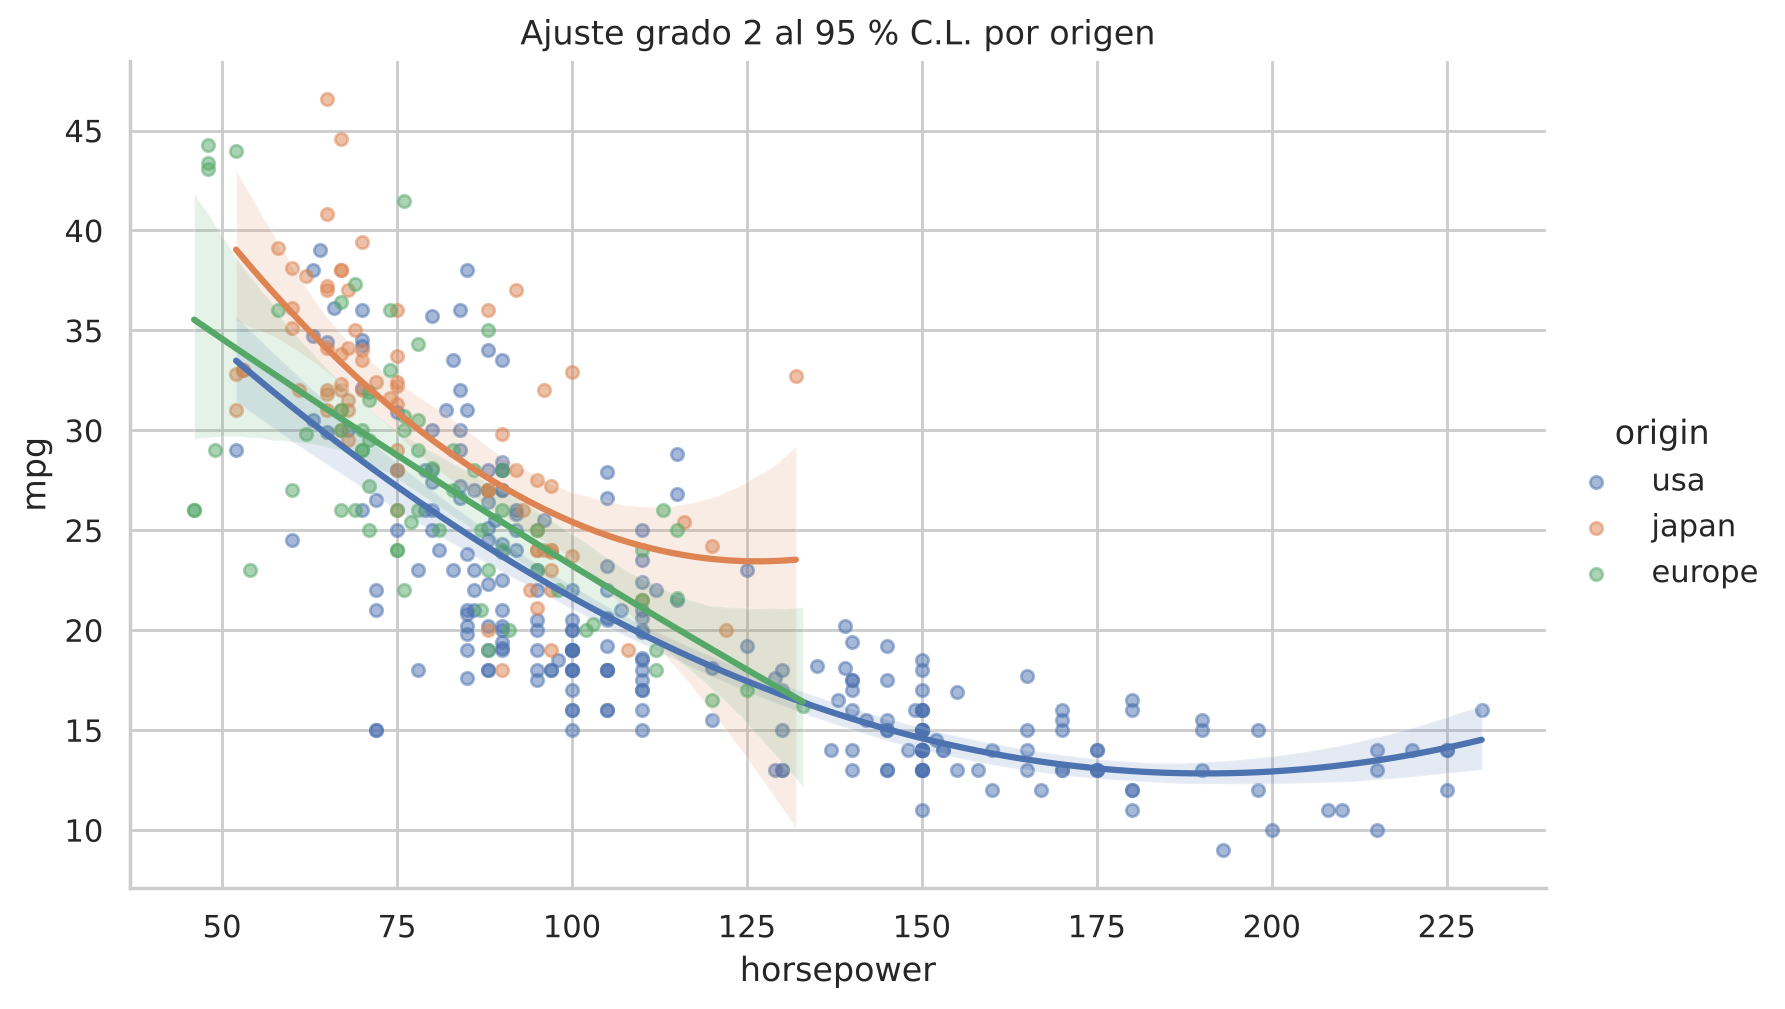

In [13]:
print(datos.groupby("origin")[["mpg", "horsepower"]].agg(["mean", "std", "count"]).round(2))

sns.lmplot(data=datos, x="horsepower", y="mpg", hue="origin",
           order=grado, ci=95, height=5, aspect=1.6,
           scatter_kws={"alpha": 0.5, "s": 20})
plt.title("Ajuste grado 2 al 95 % C.L. por origen")
plt.show()

### 1.10 Conclusiones

1. **Relación fuerte y negativa.** A más potencia, menos millas por galón. Pearson da $r \approx -0.78$ y Spearman $\rho \approx -0.85$, ambos con $p \ll 0.05$. Como $|\rho| > |r|$, la relación es monótona pero **no lineal**.
2. **El mejor modelo es cuadrático.** El ajuste es aproximadamente $mpg \approx 0.00123\,hp^2 - 0.466\,hp + 56.9$, con $R^2 \approx 0.69$ frente a $0.61$ del lineal. Grado 3 o 4 no mejoran de forma apreciable y empeoran AIC y BIC, así que agregarlos es sobreajuste.
3. **Interpretación física.** El rendimiento cae rápido entre 50 y 150 hp y luego se aplana. El vértice de la parábola (~190 hp) no significa que el rendimiento "suba otra vez": allí hay pocos datos y la banda del 95 % se ensancha, así que no se debe extrapolar.
4. **Banda del 95 % C.L.** La banda de confianza (curva media) es angosta donde hay muchos datos (70–130 hp) y se abre en los extremos. La banda de predicción es mucho más ancha (≈ ±8.6 mpg): la potencia sola no predice con precisión el consumo de un carro concreto (RMSE ≈ 4.4 mpg).
5. **Residuos.** Están centrados en cero y sin una curva clara, pero el test de Shapiro-Wilk rechaza normalidad exacta y la dispersión crece en la zona de baja potencia. Esto indica que faltan variables (peso, cilindros, año del modelo).
6. **Origen.** Los carros de EE. UU. tienen en promedio más potencia (~119 hp) y menor rendimiento (~20 mpg) que los de Europa y Japón (~80 hp, 28–30 mpg). Parte de la correlación global viene de esa diferencia entre grupos.

## Punto 2

Figura 6 de Restrepo, Rivera y Tangarife, *Phys. Rev. D* **100**, 035029 (2019): plano $M_\Psi - M_N$. Según el pie de figura:

* **Puntos azules:** dan la densidad reliquia correcta, $\Omega h^2 = 0.120 \pm 0.001$ aceptada a $3\sigma$, es decir $0.117 \le \Omega \le 0.123$.
* **Región rosada:** sobreabundancia ($\Omega_{\chi_1^0} > \Omega_{DM}$) o subabundancia ($\Omega_{\chi_1^0} < \Omega_{DM}$).

Aquí las regiones **no se dibujan a mano**: se obtienen filtrando el DataFrame con `pandas` según el valor de `Omega`.

In [14]:
url = "https://raw.githubusercontent.com/anferivera/SDdiracDM/master/general-scan.csv"
df2 = pd.read_csv(url)
df2.head()

,Unnamed: 0,MDF,MS12,MS22,LamS1H,LamS2H,LamSPH,LamS,LamSP,vS,...,U,mueg,taumug,sv,ZH11,ZH12,ZH21,ZH22,BRh1gg,BRh2gg
0,0,396.848661,2.137304e+06,2.137304e+06,0.020984,0.020984,0.020052,0.0,0.217236,702.109163,...,0.001075,0.0,1.773785e-19,1.860000e-26,0.999293,-0.037599,0.037599,0.999293,0.002837,0.000000
1,1,5988.499243,1.889315e+07,1.889315e+07,0.023341,0.023341,0.000181,0.0,0.019173,329.668504,...,-0.002513,0.0,1.791040e-18,2.580000e-31,0.001084,-0.999999,-0.999999,-0.001084,0.000342,0.002816
2,2,452.875632,2.469280e+06,2.469280e+06,0.000490,0.000490,0.017861,0.0,0.337367,3843.138599,...,0.000638,0.0,4.833919e-18,1.220000e-26,0.999994,-0.003384,0.003384,0.999994,0.002822,0.000000
3,3,589.443344,9.826674e+07,9.826674e+07,0.042790,0.042790,0.031174,0.0,0.270921,314.258778,...,0.000181,0.0,9.406560e-16,2.740000e-30,0.979480,-0.201541,0.201541,0.979480,0.002838,0.000194
4,4,1092.250036,2.054042e+06,2.054042e+06,0.002196,0.002196,0.002346,0.0,0.046671,13048.623894,...,0.000066,0.0,1.002187e-13,1.970000e-26,1.000000,-0.000945,0.000945,1.000000,0.002827,0.000000


In [15]:
df2.columns

Index(['Unnamed: 0', 'MDF', 'MS12', 'MS22', 'LamS1H', 'LamS2H', 'LamSPH',
       'LamS', 'LamSP', 'vS', 'YRD', 'YRC', 'YRA11', 'YRA12', 'YRA13', 'YRA21',
       'YRA22', 'YRA23', 'YRB11', 'YRB12', 'YRB13', 'YRB21', 'YRB22', 'YRB23',
       'mh1', 'mh2', 'mv3', 'mv2', 'mv1', 'mS1', 'mS2', 'mCha', 'mChi1',
       'mChi2', 'XV11', 'XV12', 'XV21', 'XV22', 'XU11', 'XU12', 'XU21', 'XU22',
       'vevSM', 'Omega', 'PSI', 'PSD', 'NSI', 'NSD', 'T', 'S', 'U', 'mueg',
       'taumug', 'sv', 'ZH11', 'ZH12', 'ZH21', 'ZH22', 'BRh1gg', 'BRh2gg'],
      dtype='str')

### 2.1 Variables físicas

$M_N = h_s\,v_s/\sqrt{2}$. En el scan, `YRC` (= $h_s$) puede ser negativo; la masa física es el valor absoluto.

In [16]:
df2["M_N"] = np.abs(df2["YRC"] * df2["vS"] / np.sqrt(2))
df2["M_Psi"] = df2["MDF"]
df2["M_chi1"] = df2["mChi1"]

print(f"Puntos con YRC < 0: {(df2['YRC'] < 0).sum()} de {len(df2)}")
df2[["M_Psi", "M_N", "M_chi1", "Omega"]].describe()

Puntos con YRC < 0: 10537 de 17396


,M_Psi,M_N,M_chi1,Omega
count,17396.000000,17396.000000,17396.000000,1.739600e+04
mean,1238.216377,9900.207885,841.714438,2.487003e+02
std,1104.781057,27378.528951,437.987215,3.008210e+04
min,100.090342,0.009003,2.629543,4.330000e-05
25%,1068.193894,320.577548,378.526324,1.170000e-01
50%,1118.126886,1812.923254,1106.186085,1.200000e-01
75%,1145.966273,6745.064399,1131.829238,1.230000e-01
max,9959.865042,616136.374541,2957.042850,3.950000e+06


### 2.2 Clasificación con filtros de `pandas`

In [17]:
Omega_DM = 0.12
sigma = 0.001
lim_inf, lim_sup = Omega_DM - 3 * sigma, Omega_DM + 3 * sigma   # 0.117, 0.123

correcta = df2["Omega"].between(lim_inf, lim_sup)          # Ω ≈ Ω_DM
sub = df2["Omega"] < lim_inf                                # Ω < Ω_DM
sobre = df2["Omega"] > lim_sup                              # Ω > Ω_DM

df2.loc[sub, "region"] = r"$\Omega_{\chi_1^0} < \Omega_{DM}$"
df2.loc[sobre, "region"] = r"$\Omega_{\chi_1^0} > \Omega_{DM}$"
df2.loc[correcta, "region"] = r"$\Omega h^2 - m_{\nu_\alpha}$"

df_correctos = df2[correcta]
df_incorrectos = df2[~correcta]

print(df2["region"].value_counts())

region
$\Omega h^2 - m_{\nu_\alpha}$        9265
$\Omega_{\chi_1^0} < \Omega_{DM}$    4324
$\Omega_{\chi_1^0} > \Omega_{DM}$    3807
Name: count, dtype: int64


In [18]:
# ¿Quién es la materia oscura? Comparamos M_chi1 con min(M_Psi, M_N)
df_correctos = df_correctos.assign(
    tipo_DM=np.where(df_correctos["M_N"] < df_correctos["M_Psi"], "tipo singlete (M_N < M_Ψ)", "tipo doblete (M_Ψ < M_N)")
)
print(df_correctos["tipo_DM"].value_counts())
print("\nCorrelación entre M_chi1 y min(M_Ψ, M_N):",
      round(np.corrcoef(df2["M_chi1"], np.minimum(df2["M_Psi"], df2["M_N"]))[0, 1], 3))

tipo_DM
tipo doblete (M_Ψ < M_N)     6260
tipo singlete (M_N < M_Ψ)    3005
Name: count, dtype: int64

Correlación entre M_chi1 y min(M_Ψ, M_N): 0.957


### 2.3 Reconstrucción de la figura 6

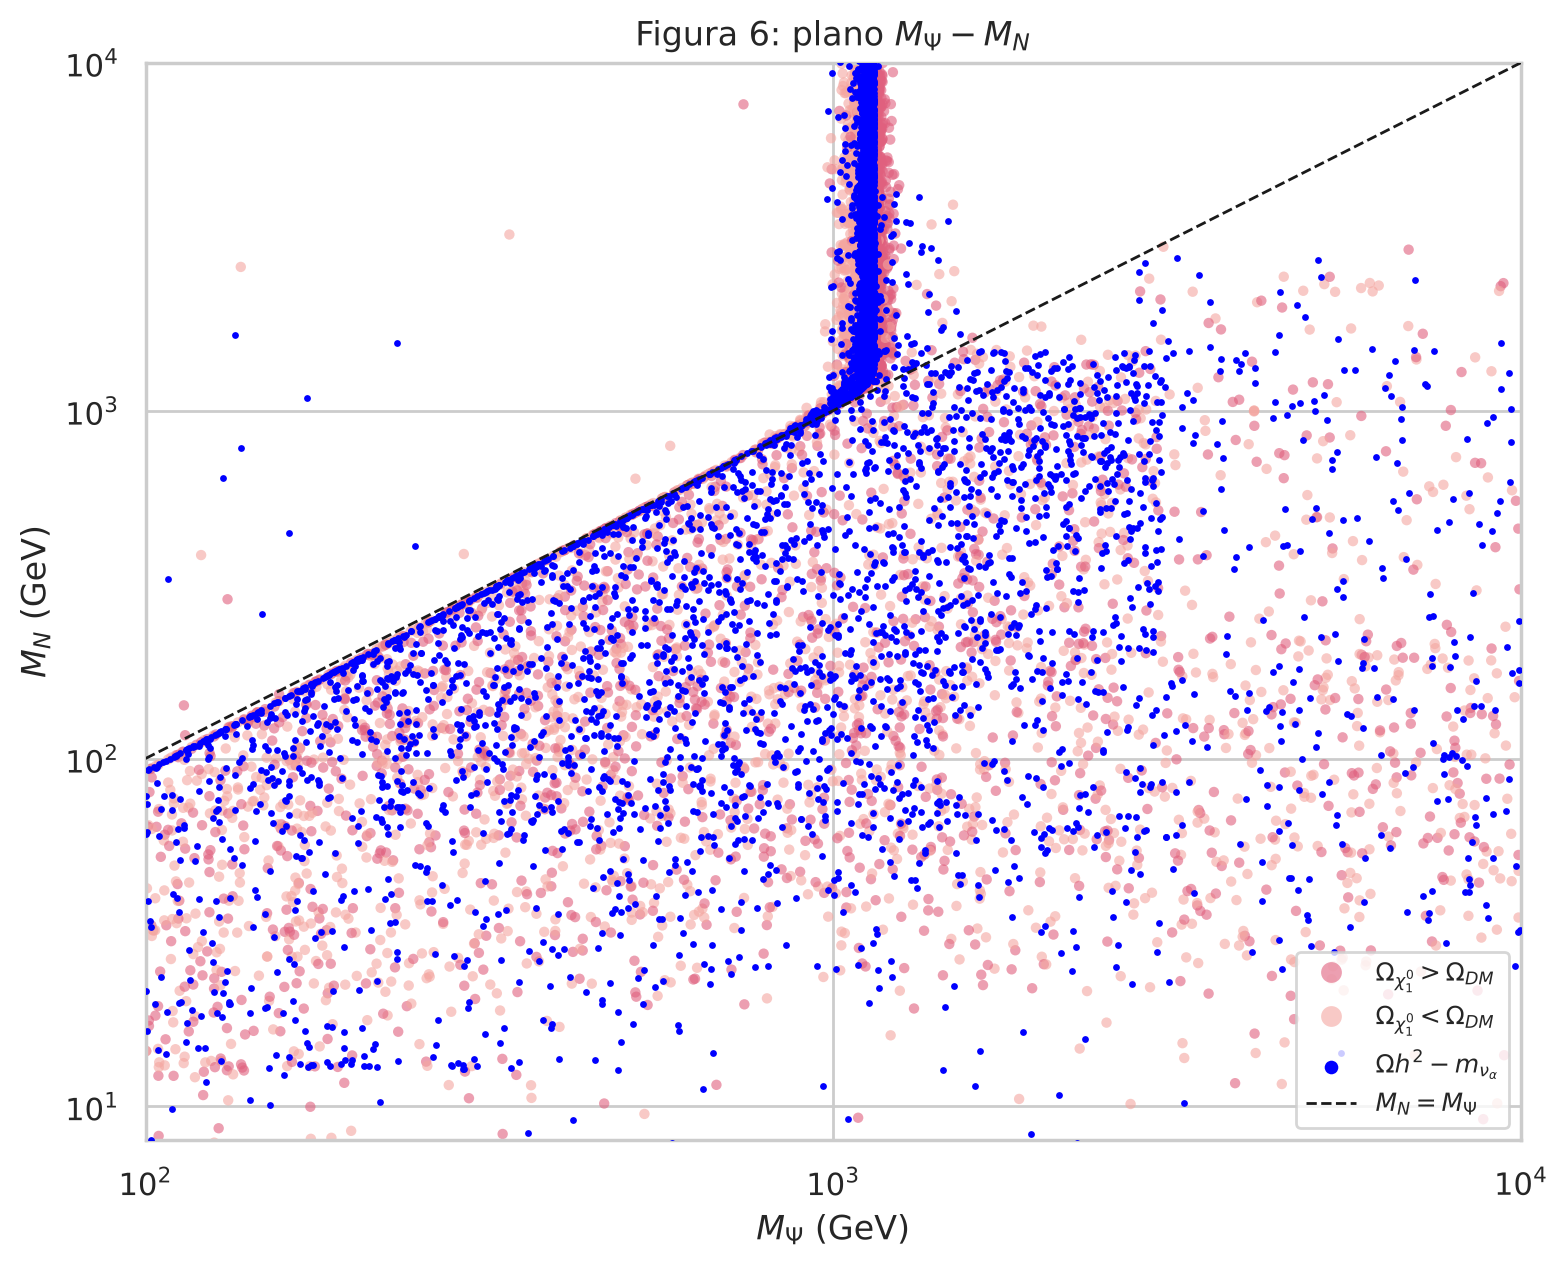

In [19]:
colores = {
    r"$\Omega_{\chi_1^0} < \Omega_{DM}$": "#f4a6a0",
    r"$\Omega_{\chi_1^0} > \Omega_{DM}$": "#e0607e",
}

fig, ax = plt.subplots(figsize=(8, 6.5))

# Fondo rosado: puntos con densidad reliquia incorrecta (filtro de pandas)
sns.scatterplot(data=df_incorrectos, x="M_Psi", y="M_N", hue="region",
                palette=colores, s=14, alpha=0.6, linewidth=0, ax=ax, zorder=1)

# Puntos azules: Ω ≈ Ω_DM
sns.scatterplot(data=df_correctos, x="M_Psi", y="M_N", color="blue",
                s=6, linewidth=0, label=r"$\Omega h^2 - m_{\nu_\alpha}$", ax=ax, zorder=3)

# Línea M_N = M_Ψ (separa DM tipo singlete y tipo doblete)
lin = np.array([1e2, 1e4])
ax.plot(lin, lin, "k--", lw=1, label=r"$M_N = M_\Psi$", zorder=4)

ax.set(xscale="log", yscale="log", xlim=(1e2, 1e4), ylim=(8, 1e4),
       xlabel=r"$M_\Psi$ (GeV)", ylabel=r"$M_N$ (GeV)",
       title="Figura 6: plano $M_\\Psi - M_N$")
ax.legend(loc="lower right", frameon=True, markerscale=2, fontsize=9)
plt.tight_layout()
plt.show()

### 2.4 Figura complementaria: masa de la materia oscura

Solo los puntos con densidad reliquia correcta, coloreados por $M_{\chi_1^0}$.

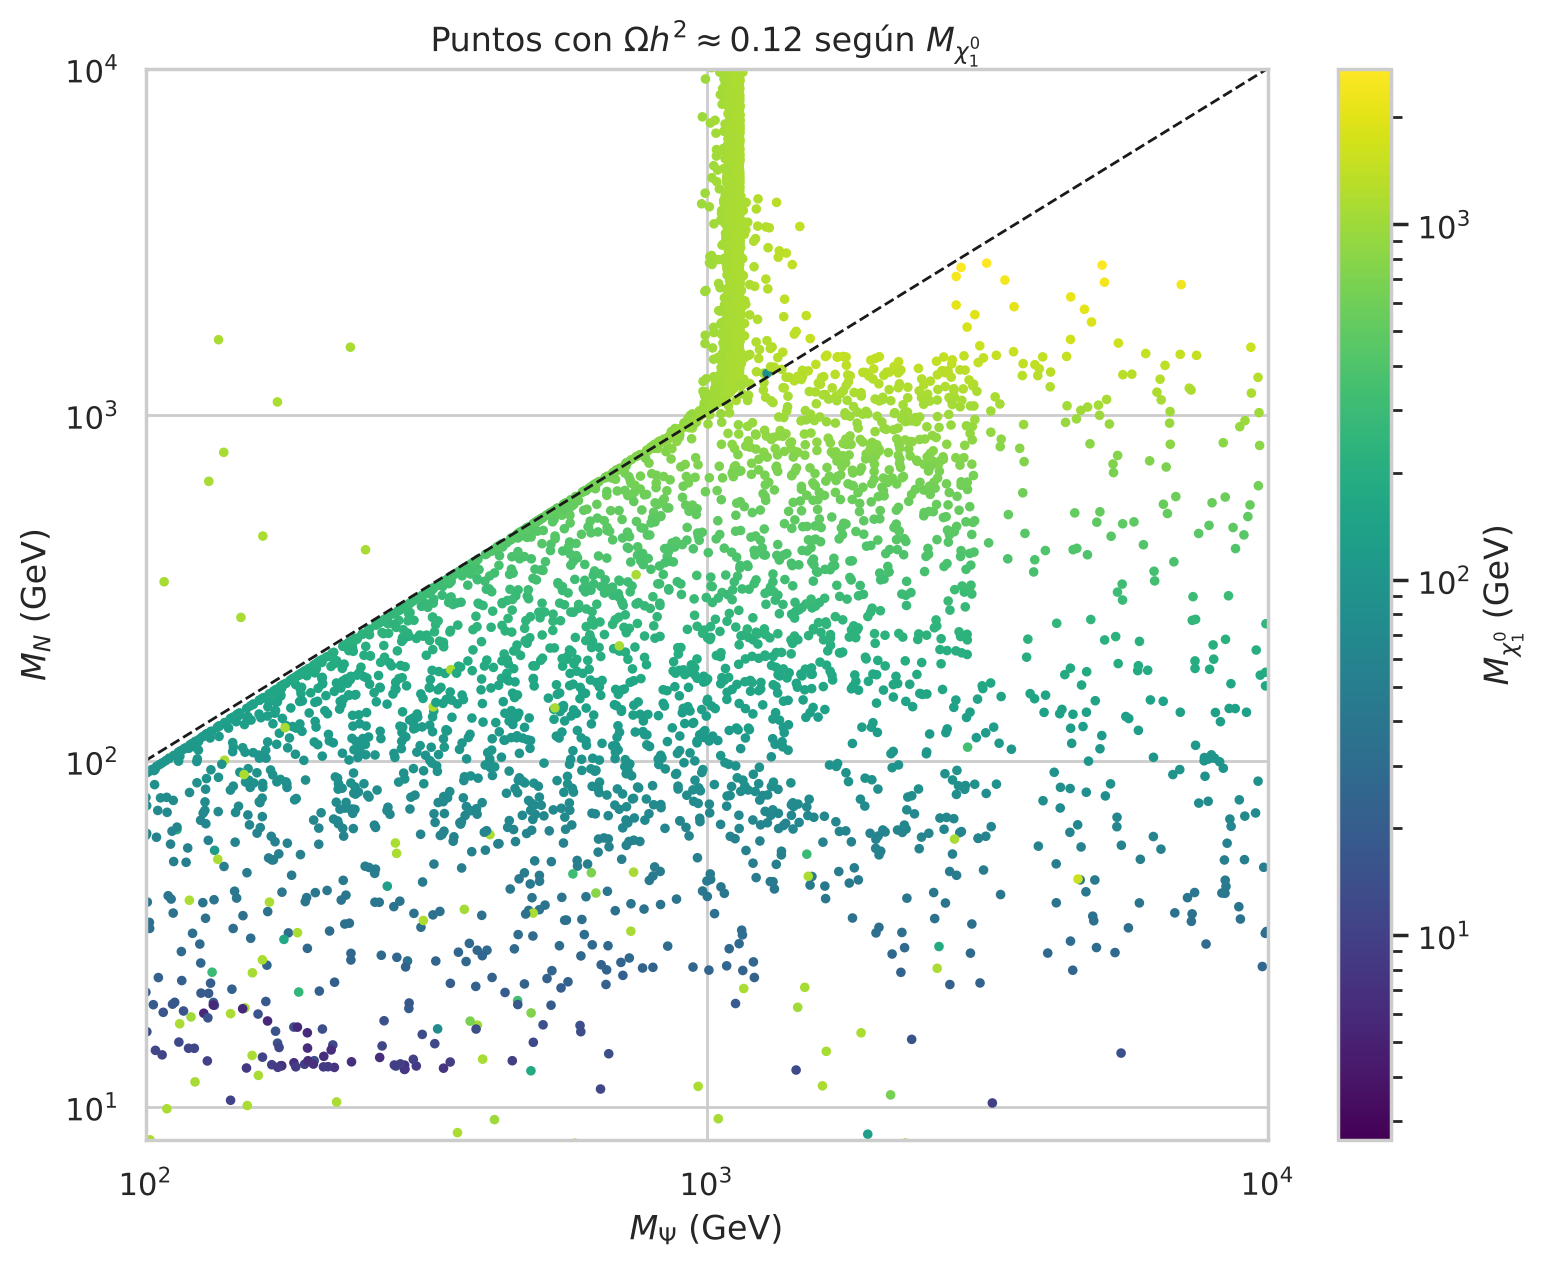

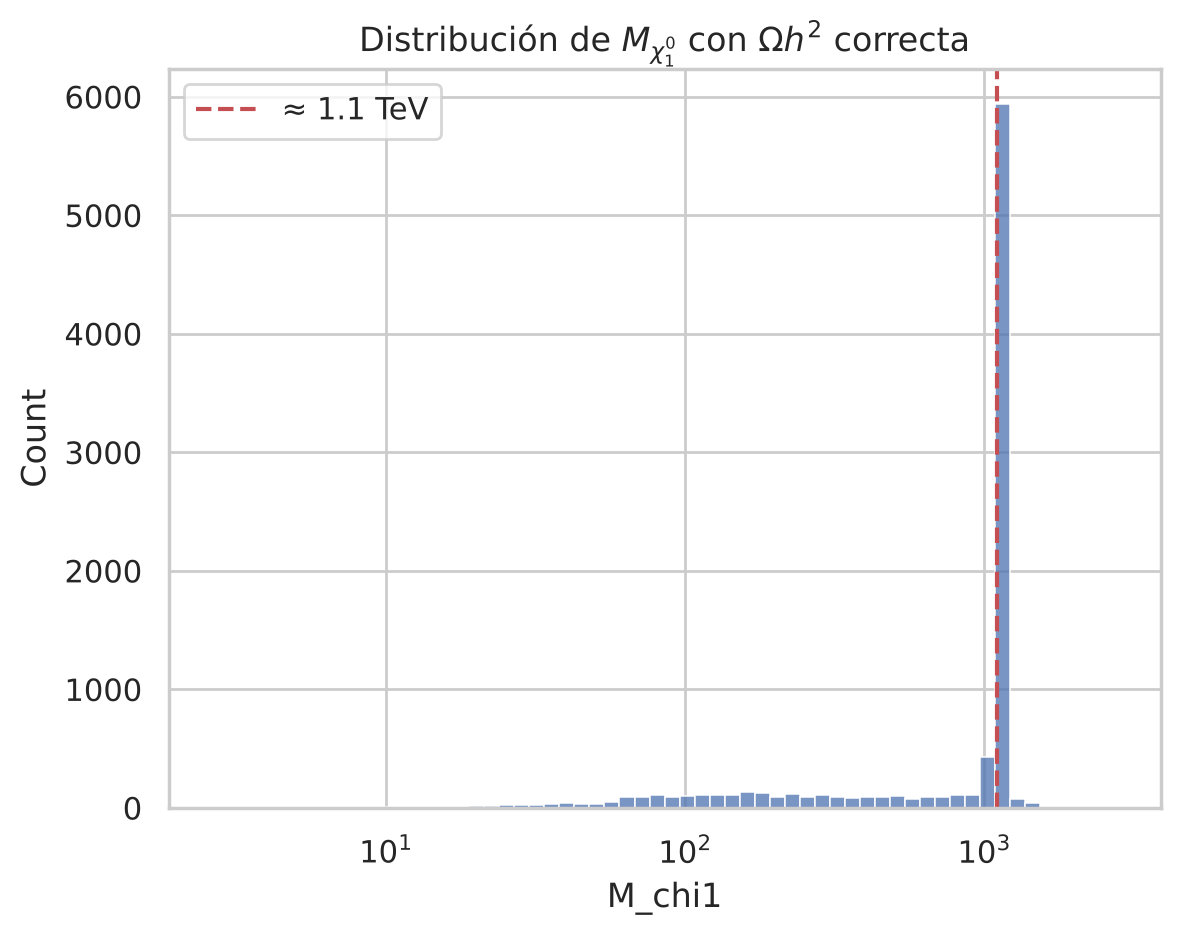

In [20]:
fig, ax = plt.subplots(figsize=(8, 6.5))
pts = ax.scatter(df_correctos["M_Psi"], df_correctos["M_N"],
                 c=df_correctos["M_chi1"], cmap="viridis", s=6,
                 norm=plt.matplotlib.colors.LogNorm())
fig.colorbar(pts, ax=ax, label=r"$M_{\chi_1^0}$ (GeV)")
ax.plot(lin, lin, "k--", lw=1)
ax.set(xscale="log", yscale="log", xlim=(1e2, 1e4), ylim=(8, 1e4),
       xlabel=r"$M_\Psi$ (GeV)", ylabel=r"$M_N$ (GeV)",
       title=r"Puntos con $\Omega h^2 \approx 0.12$ según $M_{\chi_1^0}$")
plt.tight_layout()
plt.show()

sns.histplot(data=df_correctos, x="M_chi1", bins=60, log_scale=True)
plt.axvline(1100, color="r", ls="--", label="≈ 1.1 TeV")
plt.legend()
plt.title(r"Distribución de $M_{\chi_1^0}$ con $\Omega h^2$ correcta")
plt.show()

### 2.5 Conclusiones del punto 2

* Las regiones de la figura salen directamente de filtrar `Omega` con `pandas` (`between`, `<`, `>`), sin dibujar polígonos a mano.
* La frontera diagonal $M_N = M_\Psi$ separa el caso en que la materia oscura es mayormente **singlete** ($M_N < M_\Psi$) del caso mayormente **doblete** ($M_\Psi < M_N$). Se confirma porque $M_{\chi_1^0} \approx \min(M_\Psi, M_N)$ (correlación ≈ 0.96).
* La franja vertical en $M_\Psi \approx 1.1$ TeV es el doblete puro: ahí $\Omega h^2 = 0.12$ casi sin importar $M_N$, de acuerdo con el resultado del artículo de que $m_{\chi_1^0} \lesssim 1.1$ TeV.
* La región verde del artículo (excluida por detección directa) no se puede reconstruir exactamente porque el CSV no trae las curvas de límite de XENON1T/PandaX; se tendrían que digitalizar del artículo y comparar con las columnas `PSI`/`NSI`.